In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense


In [ ]:
from google.colab import files
uploaded = files.upload()


Saving DATASETS_company_domains_final.xlsx to DATASETS_company_domains_final.xlsx


In [ ]:
import os

print(os.listdir("/content"))

['.config', 'DATASETS_company_domains_final.xlsx', 'sample_data']


In [ ]:
import pandas as pd

file_path = "/content/DATASETS_company_domains_final.xlsx"

print(os.path.exists(file_path))

True


In [ ]:
excel_data = pd.ExcelFile(file_path)

print(excel_data.sheet_names)

['Placed_Unplaced_Dataset', 'Placement_Stats', 'Company_Data', 'DTU', 'IGDTUW', 'MAIT', 'BPIT', 'IIIT_Delhi', 'Company_Comparison', '5_Year_Company_Matrix', 'MAIT_Company_5Year', '5Y_FINAL_COMPANY_TRACKING', 'Company_Dropoff_New_Repeated', '5Y_DTU', '5Y_IGDTUW', '5Y_MAIT', '5Y_BPIT', '5Y_IIITD', '5Y_PLACED_UNPLACED', 'Company_Domain_Tech', 'DATA_DTU_PLACED_UNPLACED', 'DATA_IGDTUW_PLACED_UNPLACED', 'DATA_MAIT_PLACED_UNPLACED', 'DATA_BPIT_PLACED_UNPLACED', 'DATA_IIITD_PLACED_UNPLACED', 'Graph_DTU', 'Graph_IGDTUW', 'Graph_MAIT', 'Graph_BPIT', 'Graph_IIITD']


In [ ]:
college_sheets = [
    "DTU",
    "IGDTUW",
    "MAIT",
    "BPIT",
    "IIIT_Delhi"
]

all_data = []

for sheet in college_sheets:
    temp_df = pd.read_excel(
        file_path,
        sheet_name=sheet
    )

    temp_df["College"] = sheet
    all_data.append(temp_df)

df = pd.concat(
    all_data,
    ignore_index=True
)

print("Combined shape:", df.shape)
df.head()

Combined shape: (490, 7)


,College,Year / Period,Company,Status,Technology Domain,Source,Notes
0,DTU,2020-24 recurring official recruiter set,Google,Recurring / multi-year official recruiter,"AI/ML, Cloud Computing, Software Engineering, ...",NaN,NaN
1,DTU,2020-24 recurring official recruiter set,Microsoft,Recurring / multi-year official recruiter,"Cloud Computing, AI/ML, Software Engineering, ...",NaN,NaN
2,DTU,2020-24 recurring official recruiter set,Amazon,Recurring / multi-year official recruiter,Cloud computing / E-commerce / AI / Software D...,NaN,NaN
3,DTU,2020-24 recurring official recruiter set,Adobe,Recurring / multi-year official recruiter,"Software Development ,SaaS , UI/UX Design, AI/...",NaN,NaN
4,DTU,2020-24 recurring official recruiter set,Samsung,Recurring / multi-year official recruiter,"Consumer Electronics, Semiconductor, Mobile Te...",NaN,NaN


In [ ]:
print(df.columns.tolist())

['College', 'Year / Period', 'Company', 'Status', 'Technology Domain', 'Source', 'Notes']


In [ ]:
domain_df = df.copy()

domain_df["Technology Domain"] = (
    domain_df["Technology Domain"]
    .fillna("")
    .str.split(",")
)

domain_df = domain_df.explode("Technology Domain")

domain_df["Technology Domain"] = (
    domain_df["Technology Domain"]
    .str.strip()
)

print("Total rows after splitting:", len(domain_df))
print("Number of technology domains:",
      domain_df["Technology Domain"].nunique())

Total rows after splitting: 2284
Number of technology domains: 428


In [ ]:
yearly_domain_df = domain_df[
    domain_df["Year / Period"]
    .astype(str)
    .str.match(r"^\d{4}-\d{2}$", na=False)
].copy()

yearly_domain_df["Year"] = (
    yearly_domain_df["Year / Period"]
    .str[:4]
    .astype(int)
)

yearly_domain_df = yearly_domain_df[
    yearly_domain_df["Year"].between(2020, 2024)
]

print("Years:", sorted(yearly_domain_df["Year"].unique()))
print("Rows:", len(yearly_domain_df))

Years: [np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]
Rows: 1819


In [ ]:
technology_demand = (
    yearly_domain_df
    .groupby(["Year", "Technology Domain"])
    .size()
    .reset_index(name="Demand")
)

print(technology_demand.head(10))

   Year          Technology Domain  Demand
0  2020                                  2
1  2020            / IT Consulting       1
2  2020                         5G       1
3  2020                         AI       3
4  2020                    AI / ML       5
5  2020                      AI/ML      35
6  2020  API / Software Technology       1
7  2020            API/Integration       4
8  2020                       APIs       3
9  2020  APIs / Backend Technology       1


In [ ]:
technology_matrix = technology_demand.pivot(
    index="Year",
    columns="Technology Domain",
    values="Demand"
).fillna(0)

technology_matrix = technology_matrix.sort_index()

print("Matrix shape:", technology_matrix.shape)
print("Years:", technology_matrix.index.tolist())

Matrix shape: (5, 350)
Years: [2020, 2021, 2022, 2023, 2024]


In [ ]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

scaled_data = scaler.fit_transform(
    technology_matrix.values
)

print("Scaled data shape:", scaled_data.shape)

Scaled data shape: (5, 350)


In [ ]:
sequence_length = 2

X = []
y = []

for i in range(len(scaled_data) - sequence_length):
    X.append(
        scaled_data[i:i + sequence_length]
    )

    y.append(
        scaled_data[i + sequence_length]
    )

X = np.array(X)
y = np.array(y)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (3, 2, 350)
y shape: (3, 350)


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

model = Sequential()

model.add(
    LSTM(
        64,
        activation="tanh",
        input_shape=(X.shape[1], X.shape[2])
    )
)

model.add(
    Dense(X.shape[2])
)

model.compile(
    optimizer="adam",
    loss="mse"
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │       106,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 350)            │        22,750 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 128,990 (503.87 KB)

 Trainable params: 128,990 (503.87 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model.fit(
    X,
    y,
    epochs=100,
    batch_size=1,
    verbose=1
)

Epoch 1/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.2214
Epoch 2/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.2004
Epoch 3/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.1832 
Epoch 4/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.1672
Epoch 5/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.1476
Epoch 6/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.1288
Epoch 7/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.1150 
Epoch 8/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0999
Epoch 9/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0884
Epoch 10/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0776 
Epoch 11/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0677 
Epoch 12/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0575 
Epoch 13/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0482
Epoch 14/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0412
Epoch 15/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0339
Epoch 16/100
3

In [ ]:
future_years = [2025, 2026, 2027, 2028, 2029]

current_sequence = scaled_data[-sequence_length:].copy()

future_predictions = []

for year in future_years:

    # LSTM input
    input_sequence = current_sequence.reshape(
        1,
        sequence_length,
        scaled_data.shape[1]
    )

    # Next year prediction
    next_prediction = model.predict(
        input_sequence,
        verbose=0
    )[0]

    # Demand negative nahi ho sakti
    next_prediction = np.maximum(
        next_prediction,
        0
    )

    future_predictions.append(next_prediction)

    # Predicted year ko next input sequence mein add karo
    current_sequence = np.vstack([
        current_sequence[1:],
        next_prediction
    ])

future_predictions = np.array(future_predictions)

print("Prediction shape:", future_predictions.shape)

Prediction shape: (5, 350)


In [ ]:
future_predictions_original = scaler.inverse_transform(
    future_predictions
)

# Demand negative nahi honi chahiye
future_predictions_original = np.maximum(
    future_predictions_original,
    0
)

# 2 decimal places
future_predictions_original = np.round(
    future_predictions_original,
    2
)

In [ ]:
future_df = pd.DataFrame(
    future_predictions_original,
    index=future_years,
    columns=technology_matrix.columns
)

future_df.index.name = "Year"

print(future_df)

Technology Domain        / IT Consulting  4G/5G    5G    AI  AI / Data  \
Year                                                                     
2025               1.00             0.23   0.08  0.00  2.34       0.00   
2026               1.19             0.25   0.10  0.20  1.04       0.00   
2027               1.19             0.13   0.06  0.19  1.42       0.05   
2028               1.10             0.08   0.05  0.11  1.78       0.00   
2029               1.08             0.11   0.06  0.10  1.60       0.00   

Technology Domain  AI / Data Science  AI / ML  AI / Machine Learning  \
Year                                                                   
2025                            0.04     5.80                   0.65   
2026                            0.08     3.92                   0.40   
2027                            0.04     4.13                   0.47   
2028                            0.02     4.46                   0.45   
2029                            0.03     4.17    

In [ ]:
average_future_demand = (
    future_df.mean()
    .sort_values(ascending=False)
)

top_10_technologies = average_future_demand.head(10)

print("Top 10 predicted technologies:")
print(top_10_technologies)

Top 10 predicted technologies:
Technology Domain
AI/ML                   22.556000
Cybersecurity           15.316000
Software Engineering    12.056000
Data & Analytics        11.544001
Software Development     9.144000
Data Analytics           9.000000
Cloud                    7.572000
AI / ML                  4.496000
Cloud Computing          4.488000
DevOps                   4.058000
dtype: float32


In [ ]:
# All technologies with predictions for 2025-2029
all_technology_forecast = future_df.T

all_technology_forecast.columns = [
    "2025", "2026", "2027", "2028", "2029"
]

print(all_technology_forecast)

                          2025  2026  2027  2028  2029
Technology Domain                                     
                          1.00  1.19  1.19  1.10  1.08
/ IT Consulting           0.23  0.25  0.13  0.08  0.11
4G/5G                     0.08  0.10  0.06  0.05  0.06
5G                        0.00  0.20  0.19  0.11  0.10
AI                        2.34  1.04  1.42  1.78  1.60
...                        ...   ...   ...   ...   ...
data science              0.29  0.06  0.04  0.08  0.08
data security             0.16  0.13  0.07  0.05  0.07
financial services        0.16  0.16  0.07  0.05  0.07
software Development/SDE  0.57  0.17  0.23  0.33  0.28
software development      0.00  0.00  0.00  0.00  0.00

[350 rows x 5 columns]


In [ ]:
presence_status = all_technology_forecast.copy()

presence_status = presence_status.applymap(
    lambda x: "Expected Demand" if x > 0.5 else "Very Low/No Demand"
)

print(presence_status)

                                        2025                2026  \
Technology Domain                                                  
                             Expected Demand     Expected Demand   
/ IT Consulting           Very Low/No Demand  Very Low/No Demand   
4G/5G                     Very Low/No Demand  Very Low/No Demand   
5G                        Very Low/No Demand  Very Low/No Demand   
AI                           Expected Demand     Expected Demand   
...                                      ...                 ...   
data science              Very Low/No Demand  Very Low/No Demand   
data security             Very Low/No Demand  Very Low/No Demand   
financial services        Very Low/No Demand  Very Low/No Demand   
software Development/SDE     Expected Demand  Very Low/No Demand   
software development      Very Low/No Demand  Very Low/No Demand   

                                        2027                2028  \
Technology Domain                              

/tmp/ipykernel_538/3380498889.py:3: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  presence_status = presence_status.applymap(


In [ ]:
# 5-year change for every technology
result_analysis = future_df.T.copy()

result_analysis["5-Year Average"] = result_analysis[
    [2025, 2026, 2027, 2028, 2029]
].mean(axis=1)

result_analysis["2025-2029 Change"] = (
    result_analysis[2029] - result_analysis[2025]
)

result_analysis["Trend"] = result_analysis.apply(
    lambda row:
        "Increasing"
        if row["2025-2029 Change"] > 0
        else "Decreasing"
        if row["2025-2029 Change"] < 0
        else "Stable",
    axis=1
)

result_analysis["Future Status"] = result_analysis[
    "5-Year Average"
].apply(
    lambda x:
        "Expected Demand"
        if x > 0.5
        else "Very Low / No Demand"
)

result_analysis = result_analysis.sort_values(
    "5-Year Average",
    ascending=False
)

result_analysis

Year,2025,2026,2027,2028,2029,5-Year Average,2025-2029 Change,Trend,Future Status
Technology Domain,,,,,,,,,
AI/ML,21.51,23.530001,23.01,22.309999,22.42,22.556000,0.910000,Increasing,Expected Demand
Cybersecurity,15.05,15.310000,15.51,15.380000,15.33,15.316000,0.280000,Increasing,Expected Demand
Software Engineering,12.00,12.000000,12.28,12.000000,12.00,12.056000,0.000000,Stable,Expected Demand
Data & Analytics,11.00,11.590000,12.04,11.710000,11.38,11.544001,0.380000,Increasing,Expected Demand
Software Development,8.90,9.430000,9.56,9.070000,8.76,9.144000,-0.139999,Decreasing,Expected Demand
...,...,...,...,...,...,...,...,...,...
Technology / Software,0.00,0.000000,0.00,0.000000,0.00,0.000000,0.000000,Stable,Very Low / No Demand
analytics,0.00,0.000000,0.00,0.000000,0.00,0.000000,0.000000,Stable,Very Low / No Demand
Telecommunications,0.00,0.000000,0.00,0.000000,0.00,0.000000,0.000000,Stable,Very Low / No Demand


In [ ]:
# File ke actual Technology Domain names dekho

all_domains = (
    domain_df["Technology Domain"]
    .dropna()
    .astype(str)
    .str.strip()
)

unique_domains = sorted(all_domains.unique())

print("Total unique domains:", len(unique_domains))

for i, domain in enumerate(unique_domains, 1):
    print(i, ":", domain)

Total unique domains: 428
1 : 
2 : / IT Consulting
3 : 3D Technology
4 : 4G/5G
5 : 5G
6 : 5G/Connectivity
7 : 5G/Wireless Technology
8 : ADI Technology
9 : AI
10 : AI / Data
11 : AI / Data Science
12 : AI / ML
13 : AI / Machine Learning
14 : AI APIs / Model Integration
15 : AI Engineering
16 : AI Hardware
17 : AI Hardware & Accelerators
18 : AI Infrastructure
19 : AI Networking
20 : AI Solutins Systems Engineer
21 : AI-ML
22 : AI/GenAI
23 : AI/ML
24 : AIOps
25 : API
26 : API / Software Technology
27 : API / System Integration
Technology Consulting
28 : API Development
29 : API Development / Integration
30 : API/Integration
31 : APIs
32 : APIs / Backend Technology
33 : APIs/Integration
34 : AWS/Azure
35 : Accelerated Computing
36 : AdTech
37 : Adaptive Learning
38 : Advanced Optics
39 : Aerospace Technology
40 : Agentic AI
41 : Agricultural Machinery / Automotive Manufacturing
42 : Analog Electronics
43 : Analytics and Reporting
44 : Application Development
45 : Application Performance 

In [ ]:
import re
import pandas as pd

# Copy original data
clean_domain_df = domain_df.copy()

# Basic text cleaning
clean_domain_df["Technology Domain"] = (
    clean_domain_df["Technology Domain"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
    .str.replace(r"\.$", "", regex=True)
)

# Case normalization
clean_domain_df["Technology Domain"] = (
    clean_domain_df["Technology Domain"]
    .str.casefold()
)

# Exact duplicate labels after case/space normalization
clean_domain_df = clean_domain_df.drop_duplicates(
    subset=["Year / Period", "Company", "Technology Domain"]
)

print(
    "Domains after basic cleaning:",
    clean_domain_df["Technology Domain"].nunique()
)

Domains after basic cleaning: 414


In [ ]:
print("Before cleaning:", domain_df["Technology Domain"].nunique())
print("After basic cleaning:", clean_domain_df["Technology Domain"].nunique())

Before cleaning: 428
After basic cleaning: 414


In [ ]:
# Technology-wise total demand
technology_demand = (
    clean_domain_df[
        clean_domain_df["Technology Domain"].str.strip() != ""
    ]
    .groupby("Technology Domain")
    .size()
    .reset_index(name="Demand")
)

# Highest demand first
technology_demand = technology_demand.sort_values(
    by="Demand",
    ascending=False
)

print(technology_demand.head(20))

        Technology Domain  Demand
28                  ai/ml     202
101         cybersecurity     121
371  software engineering     112
71                  cloud     107
105      data & analytics      90
107        data analytics      83
365  software development      65
75        cloud computing      42
203               fintech      40
45             automation      36
140                devops      35
118      data engineering      30
258           it services      26
292            networking      23
18                ai / ml      22
123          data science      22
134          database/sql      21
14                     ai      21
340                  saas      21
245                   iot      18


In [ ]:
# ==========================================
# 1. GENERATE 2025–2029 PREDICTIONS
# ==========================================

future_years = [2025, 2026, 2027, 2028, 2029]

# Last 2 years of historical scaled data
current_sequence = scaled_data[-2:].copy()

future_predictions = []

for year in future_years:

    # LSTM input
    input_sequence = current_sequence.reshape(
        1,
        2,
        scaled_data.shape[1]
    )

    # Predict next year
    next_prediction = model.predict(
        input_sequence,
        verbose=0
    )[0]

    # Demand cannot be negative
    next_prediction = np.maximum(
        next_prediction,
        0
    )

    future_predictions.append(next_prediction)

    # Add prediction to sequence
    current_sequence = np.vstack([
        current_sequence[1:],
        next_prediction
    ])


# Convert list to array
future_predictions = np.array(
    future_predictions
)


# ==========================================
# 2. CONVERT BACK TO ORIGINAL DEMAND SCALE
# ==========================================

future_predictions_original = scaler.inverse_transform(
    future_predictions
)

future_predictions_original = np.maximum(
    future_predictions_original,
    0
)

future_predictions_original = np.round(
    future_predictions_original,
    2
)


# ==========================================
# 3. CREATE PREDICTION DATAFRAME
# ==========================================

future_df = pd.DataFrame(
    future_predictions_original,
    index=future_years,
    columns=technology_matrix.columns
)

future_df.index.name = "Year"


print("Predicted data:")
display(future_df)

Predicted data:


Technology Domain,,/ IT Consulting,4G/5G,5G,AI,AI / Data,AI / Data Science,AI / ML,AI / Machine Learning,AI APIs / Model Integration,...,Workflow Automation,analytics,cloud technologies,cloud-based data protection,cyber recovery,data science,data security,financial services,software Development/SDE,software development
Year,,,,,,,,,,,,,,,,,,,,,
2025,1.00,0.23,0.08,0.00,2.34,0.00,0.04,5.80,0.65,0.64,...,0.49,0.0,0.0,0.00,0.04,0.29,0.16,0.16,0.57,0.0
2026,1.19,0.25,0.10,0.20,1.04,0.00,0.08,3.92,0.40,0.25,...,0.02,0.0,0.0,0.00,0.00,0.06,0.13,0.16,0.17,0.0
2027,1.19,0.13,0.06,0.19,1.42,0.05,0.04,4.13,0.47,0.26,...,0.17,0.0,0.0,0.00,0.00,0.04,0.07,0.07,0.23,0.0
2028,1.10,0.08,0.05,0.11,1.78,0.00,0.02,4.46,0.45,0.33,...,0.27,0.0,0.0,0.01,0.03,0.08,0.05,0.05,0.33,0.0
2029,1.08,0.11,0.06,0.10,1.60,0.00,0.03,4.17,0.35,0.29,...,0.20,0.0,0.0,0.01,0.02,0.08,0.07,0.07,0.28,0.0


In [ ]:
# Year ko normal column bana do
future_df_display = future_df.reset_index()

# Year column ka naam ensure karo
future_df_display.rename(
    columns={"index": "Year"},
    inplace=True
)

display(future_df_display)

Technology Domain,Year,,/ IT Consulting,4G/5G,5G,AI,AI / Data,AI / Data Science,AI / ML,AI / Machine Learning,...,Workflow Automation,analytics,cloud technologies,cloud-based data protection,cyber recovery,data science,data security,financial services,software Development/SDE,software development
0,2025,1.00,0.23,0.08,0.00,2.34,0.00,0.04,5.80,0.65,...,0.49,0.0,0.0,0.00,0.04,0.29,0.16,0.16,0.57,0.0
1,2026,1.19,0.25,0.10,0.20,1.04,0.00,0.08,3.92,0.40,...,0.02,0.0,0.0,0.00,0.00,0.06,0.13,0.16,0.17,0.0
2,2027,1.19,0.13,0.06,0.19,1.42,0.05,0.04,4.13,0.47,...,0.17,0.0,0.0,0.00,0.00,0.04,0.07,0.07,0.23,0.0
3,2028,1.10,0.08,0.05,0.11,1.78,0.00,0.02,4.46,0.45,...,0.27,0.0,0.0,0.01,0.03,0.08,0.05,0.05,0.33,0.0
4,2029,1.08,0.11,0.06,0.10,1.60,0.00,0.03,4.17,0.35,...,0.20,0.0,0.0,0.01,0.02,0.08,0.07,0.07,0.28,0.0


In [ ]:
import pandas as pd
import numpy as np
import re

# =====================================================
# 1. LOAD EXCEL FILE
# =====================================================

file_path = "/content/DATASETS_company_domains_final.xlsx"

college_sheets = [
    "DTU",
    "IGDTUW",
    "MAIT",
    "BPIT",
    "IIIT_Delhi"
]

all_data = []

for sheet in college_sheets:
    temp = pd.read_excel(
        file_path,
        sheet_name=sheet
    )

    temp["College"] = sheet
    all_data.append(temp)

df = pd.concat(
    all_data,
    ignore_index=True
)


# =====================================================
# 2. SPLIT TECHNOLOGY DOMAIN
# =====================================================

domain_df = df.copy()

domain_df["Technology Domain"] = (
    domain_df["Technology Domain"]
    .fillna("")
    .astype(str)
    .str.split(",")
)

domain_df = domain_df.explode(
    "Technology Domain"
)

domain_df["Technology Domain"] = (
    domain_df["Technology Domain"]
    .str.strip()
)

domain_df = domain_df[
    domain_df["Technology Domain"] != ""
].copy()


# =====================================================
# 3. NORMALIZE TECHNOLOGY NAMES
# =====================================================

def normalize_technology(x):

    x = str(x).strip().casefold()
    x = re.sub(r"\s+", " ", x)
    x = x.rstrip(".")


    # AI / ML
    if x in [
        "ai",
        "ai / ml",
        "ai/ml",
        "ai-ml",
        "ai / machine learning"
    ]:
        return "AI/ML"


    # Cybersecurity
    if x in [
        "cybersecurity",
        "cyber security"
    ]:
        return "Cybersecurity"


    # Cloud
    if x in [
        "cloud",
        "cloud computing",
        "cloud technologies",
        "cloud infrastructure",
        "cloud/infrastructure",
        "cloud & infrastructure"
    ]:
        return "Cloud"


    # Data Analytics
    if x in [
        "data analytics",
        "data analytics/bi",
        "data analytics / bi",
        "data analytics & bi",
        "data analytics / data engineering",
        "data analytics / data science",
        "data & analytics",
        "analytics and reporting"
    ]:
        return "Data Analytics"


    # Data Science
    if x in [
        "data science",
        "datascience",
        "data science & analytics",
        "data science / data analytics"
    ]:
        return "Data Science"


    # Data Engineering
    if x in [
        "data engineering",
        "data engineering & analytics"
    ]:
        return "Data Engineering"


    # Software Development
    if (
        "software development" in x
        or "software developer" in x
        or "software engineer" in x
        or "software engineering" in x
        or x == "software development/sde"
        or x == "software developer/ ai/ml"
    ):
        return "Software Development"


    # Web Development
    if (
        "web development" in x
        or "web/app development" in x
        or "web & app development" in x
        or "web/mobile development" in x
    ):
        return "Web Development"


    # Full Stack
    if "full stack" in x:
        return "Full Stack"


    # FinTech
    if (
        "fintech" in x
        or "financial technology" in x
    ):
        return "FinTech"


    # DevOps
    if "devops" in x:
        return "DevOps"


    # Automation
    if (
        "automation" in x
        or x == "rpa"
        or "rpa/automation" in x
    ):
        return "Automation"


    # Database
    if (
        "database" in x
        or x == "databases"
        or "database/sql" in x
    ):
        return "Database"


    # API
    if x.startswith("api"):
        return "API"


    # UI/UX
    if "ui/ux" in x:
        return "UI/UX"


    # QA / Testing
    if (
        "qa" in x
        or "testing" in x
    ):
        return "QA/Testing"


    # Mobile
    if "mobile" in x:
        return "Mobile Development"


    # Payment
    if (
        "payment" in x
        or "payments" in x
    ):
        return "Payment Technology"


    # Blockchain
    if "blockchain" in x:
        return "Blockchain"


    # IoT
    if x == "iot" or x.startswith("iot/"):
        return "IoT"


    # NLP
    if x == "nlp":
        return "NLP"


    # Generative AI
    if (
        "genai" in x
        or "generative ai" in x
    ):
        return "Generative AI"


    # Robotics
    if "robotics" in x:
        return "Robotics"


    # Semiconductor
    if "semiconductor" in x:
        return "Semiconductor"


    # E-commerce
    if (
        "e-commerce" in x
        or "ecommerce" in x
    ):
        return "E-commerce"


    # Keep remaining technology
    return x.title()


domain_df["Technology"] = (
    domain_df["Technology Domain"]
    .apply(normalize_technology)
)


# =====================================================
# 4. KEEP YEAR-WISE DATA
# =====================================================

yearly_df = domain_df[
    domain_df["Year / Period"]
    .astype(str)
    .str.match(r"^\d{4}-\d{2}$", na=False)
].copy()

yearly_df["Year"] = (
    yearly_df["Year / Period"]
    .str[:4]
    .astype(int)
)

# 2020–2024 historical data
yearly_df = yearly_df[
    yearly_df["Year"].between(2020, 2024)
]


# =====================================================
# 5. CREATE NORMALIZED TECHNOLOGY DEMAND MATRIX
# =====================================================

technology_demand = (
    yearly_df
    .groupby(
        ["Year", "Technology"]
    )
    .size()
    .reset_index(
        name="Demand"
    )
)

technology_matrix = (
    technology_demand
    .pivot(
        index="Year",
        columns="Technology",
        values="Demand"
    )
    .fillna(0)
    .sort_index()
)


print(
    "Normalized technology matrix:"
)

display(technology_matrix)

print(
    "Number of normalized technologies:",
    technology_matrix.shape[1]
)

Normalized technology matrix:


Technology,/ It Consulting,4G/5G,5G,AI/ML,API,Adtech,Aerospace Technology,Agricultural Machinery / Automotive Manufacturing,Ai / Data,Ai / Data Science,...,Travel Technology,Traveltech / B2B Travel Technology,Tyre Manufacturing,UI/UX,Upi,Upi Technology,Vehicle Electronics,Vlsi Design,Web Development,Wordpress
Year,,,,,,,,,,,,,,,,,,,,,
2020,1.0,0.0,1.0,43.0,10.0,1.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,7.0,0.0
2021,0.0,0.0,1.0,56.0,8.0,1.0,0.0,0.0,0.0,1.0,...,1.0,1.0,0.0,3.0,0.0,2.0,0.0,0.0,9.0,0.0
2022,1.0,1.0,1.0,35.0,2.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,6.0,0.0
2023,0.0,0.0,1.0,39.0,7.0,0.0,1.0,0.0,1.0,0.0,...,0.0,0.0,0.0,2.0,1.0,0.0,1.0,0.0,5.0,0.0
2024,0.0,0.0,0.0,34.0,1.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,2.0,1.0


Number of normalized technologies: 240


In [ ]:
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

# Scale data
scaler = MinMaxScaler()

scaled_data = scaler.fit_transform(
    technology_matrix.values
)


# Sequence length
sequence_length = 2

X = []
y = []

for i in range(
    len(scaled_data) - sequence_length
):

    X.append(
        scaled_data[
            i:i + sequence_length
        ]
    )

    y.append(
        scaled_data[
            i + sequence_length
        ]
    )

X = np.array(X)
y = np.array(y)


# LSTM
model = Sequential()

model.add(
    LSTM(
        64,
        activation="tanh",
        input_shape=(
            X.shape[1],
            X.shape[2]
        )
    )
)

model.add(
    Dense(
        X.shape[2]
    )
)

model.compile(
    optimizer="adam",
    loss="mse"
)


model.fit(
    X,
    y,
    epochs=100,
    batch_size=1,
    verbose=1
)

Epoch 1/100


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.2352
Epoch 2/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.2114
Epoch 3/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.1932
Epoch 4/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.1748
Epoch 5/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.1581
Epoch 6/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.1390
Epoch 7/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.1249
Epoch 8/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.1069
Epoch 9/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0940
Epoch 10/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0828
Epoch 11/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0720
Epoch 12/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0619
Epoch 13/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0536
Epoch 14/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0455
Epoch 15/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0385
Epoch 16/100
3/3 ━━━━━━━━━━━━━━

In [ ]:
future_years = [
    2025,
    2026,
    2027,
    2028,
    2029
]

current_sequence = (
    scaled_data[-sequence_length:].copy()
)

future_predictions = []

for year in future_years:

    input_sequence = (
        current_sequence
        .reshape(
            1,
            sequence_length,
            scaled_data.shape[1]
        )
    )

    next_prediction = model.predict(
        input_sequence,
        verbose=0
    )[0]

    next_prediction = np.maximum(
        next_prediction,
        0
    )

    future_predictions.append(
        next_prediction
    )

    current_sequence = np.vstack([
        current_sequence[1:],
        next_prediction
    ])


# Convert back to original scale
future_predictions = np.array(
    future_predictions
)

future_predictions_original = (
    scaler.inverse_transform(
        future_predictions
    )
)

future_predictions_original = np.maximum(
    future_predictions_original,
    0
)

future_predictions_original = np.round(
    future_predictions_original,
    2
)


# Create final prediction dataframe
prediction_df = pd.DataFrame(
    future_predictions_original,
    index=future_years,
    columns=technology_matrix.columns
)

prediction_df.index.name = "Year"


display(prediction_df)

Technology,/ It Consulting,4G/5G,5G,AI/ML,API,Adtech,Aerospace Technology,Agricultural Machinery / Automotive Manufacturing,Ai / Data,Ai / Data Science,...,Travel Technology,Traveltech / B2B Travel Technology,Tyre Manufacturing,UI/UX,Upi,Upi Technology,Vehicle Electronics,Vlsi Design,Web Development,Wordpress
Year,,,,,,,,,,,,,,,,,,,,,
2025,0.06,0.10,0.13,34.0,1.16,0.02,0.00,0.64,0.02,0.0,...,0.00,0.05,0.48,0.00,0.00,0.21,0.55,0.00,3.05,0.64
2026,0.05,0.08,0.39,34.0,2.35,0.13,0.26,0.23,0.25,0.0,...,0.00,0.10,0.06,0.46,0.13,0.18,0.41,0.00,3.66,0.24
2027,0.02,0.06,0.22,34.0,2.02,0.06,0.17,0.34,0.19,0.0,...,0.00,0.04,0.23,0.30,0.14,0.11,0.46,0.00,3.10,0.33
2028,0.03,0.07,0.14,34.0,1.65,0.04,0.08,0.37,0.12,0.0,...,0.01,0.04,0.28,0.14,0.05,0.11,0.43,0.02,2.78,0.33
2029,0.03,0.07,0.18,34.0,1.69,0.04,0.11,0.29,0.13,0.0,...,0.01,0.04,0.19,0.21,0.06,0.10,0.37,0.00,2.84,0.25


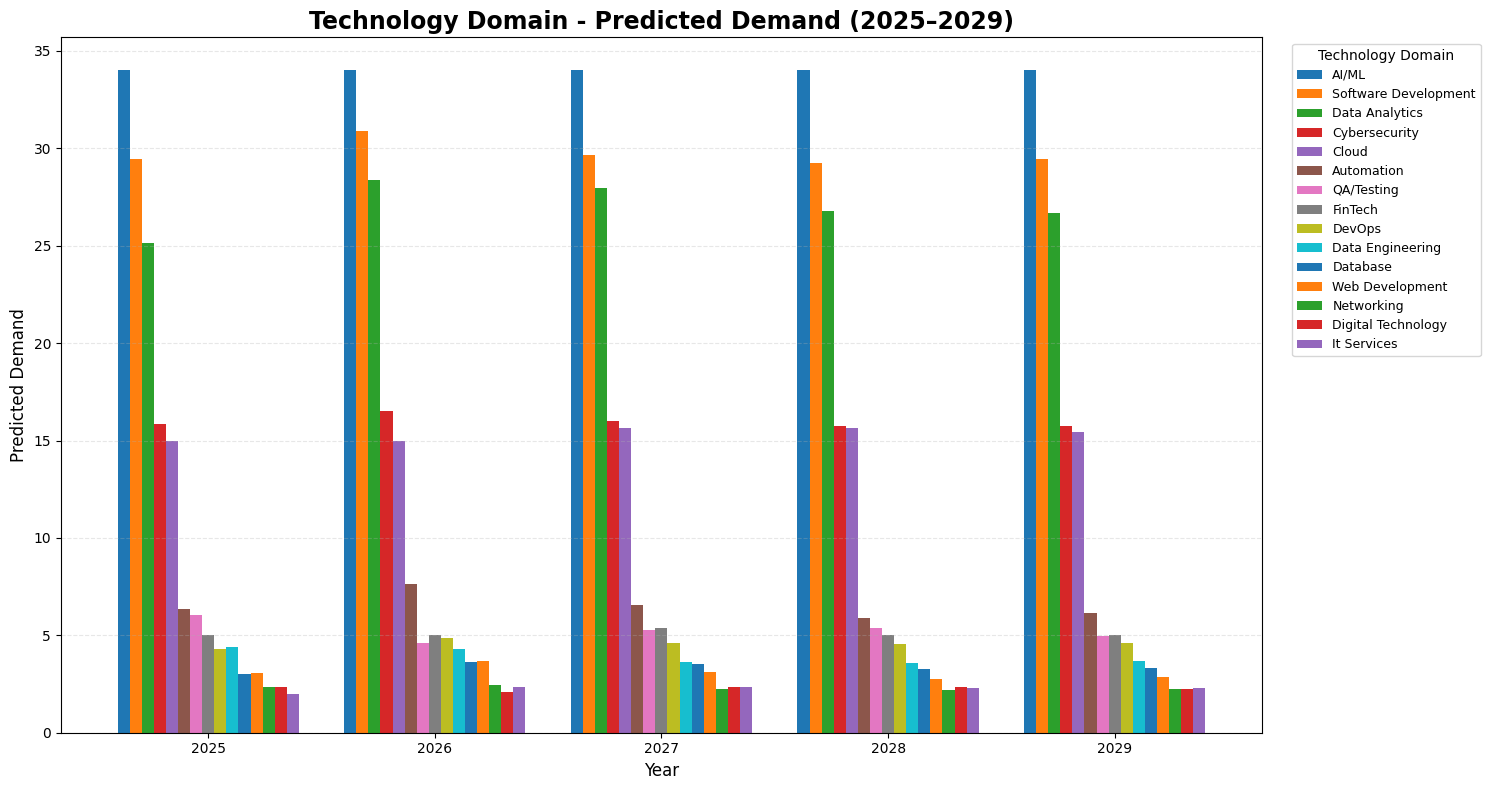

In [ ]:
# ==========================================
# TOP PREDICTED TECHNOLOGIES
# ==========================================

# 2025-2029 ka average prediction
avg_prediction = prediction_df.mean(axis=0)

# Highest demand first
avg_prediction = avg_prediction.sort_values(
    ascending=False
)

# Top 15
top_15 = avg_prediction.head(15)


# ==========================================
# BAR GRAPH - YEAR ON X-AXIS
# ==========================================

# Selected top technologies
selected_technologies = top_15.index.tolist()

# 2025-2029 ka data
plot_data = prediction_df[
    selected_technologies
]


# ==========================================
# GRAPH
# ==========================================

ax = plot_data.plot(
    kind="bar",
    figsize=(15, 8),
    width=0.8
)

plt.xlabel(
    "Year",
    fontsize=12
)

plt.ylabel(
    "Predicted Demand",
    fontsize=12
)

plt.title(
    "Technology Domain - Predicted Demand (2025–2029)",
    fontsize=17,
    fontweight="bold"
)

# X-axis = years
plt.xticks(
    ticks=range(5),
    labels=["2025", "2026", "2027", "2028", "2029"],
    rotation=0
)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

# Technology names in separate legend
plt.legend(
    title="Technology Domain",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=9
)

plt.tight_layout()
plt.show()

Total technologies: 240


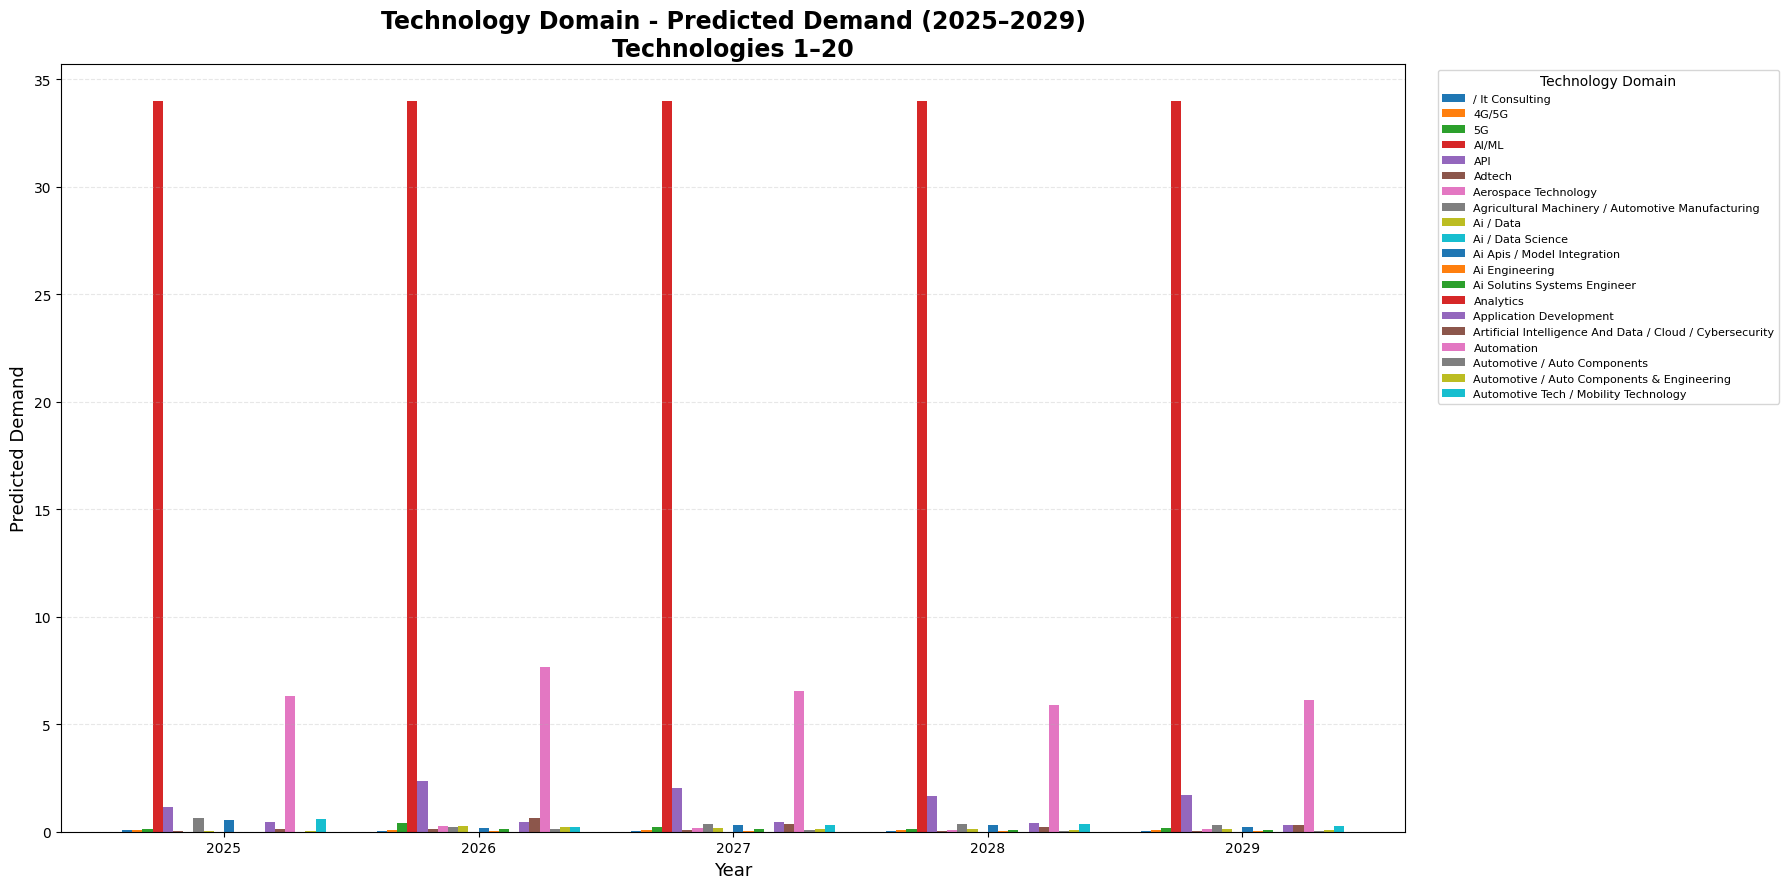

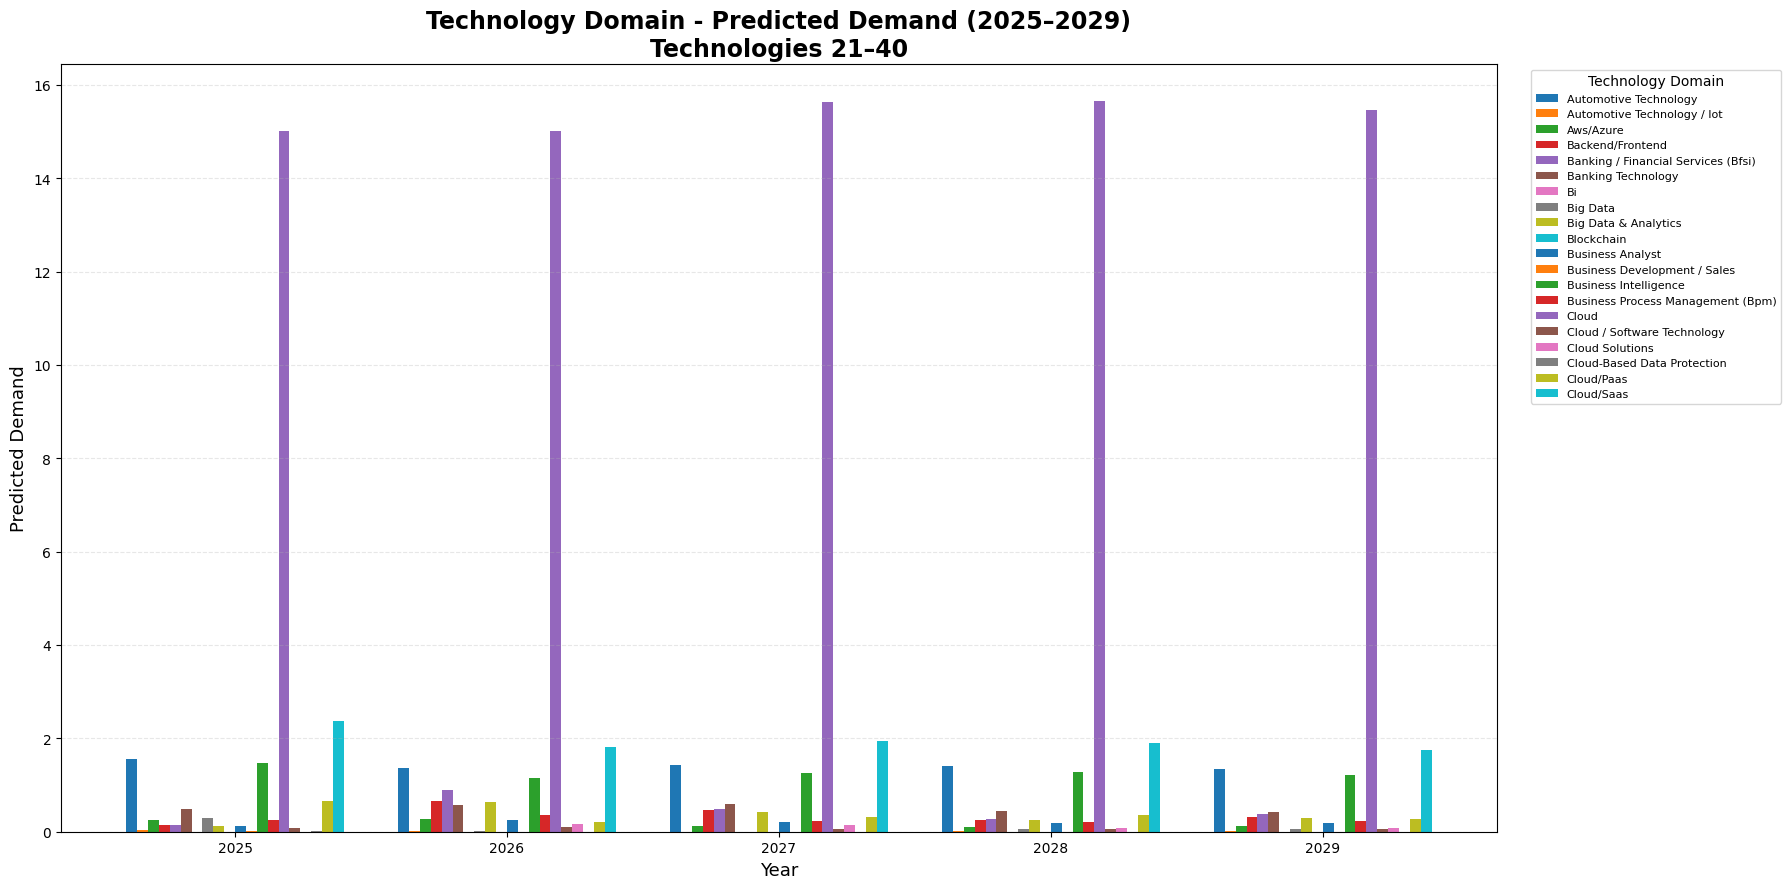

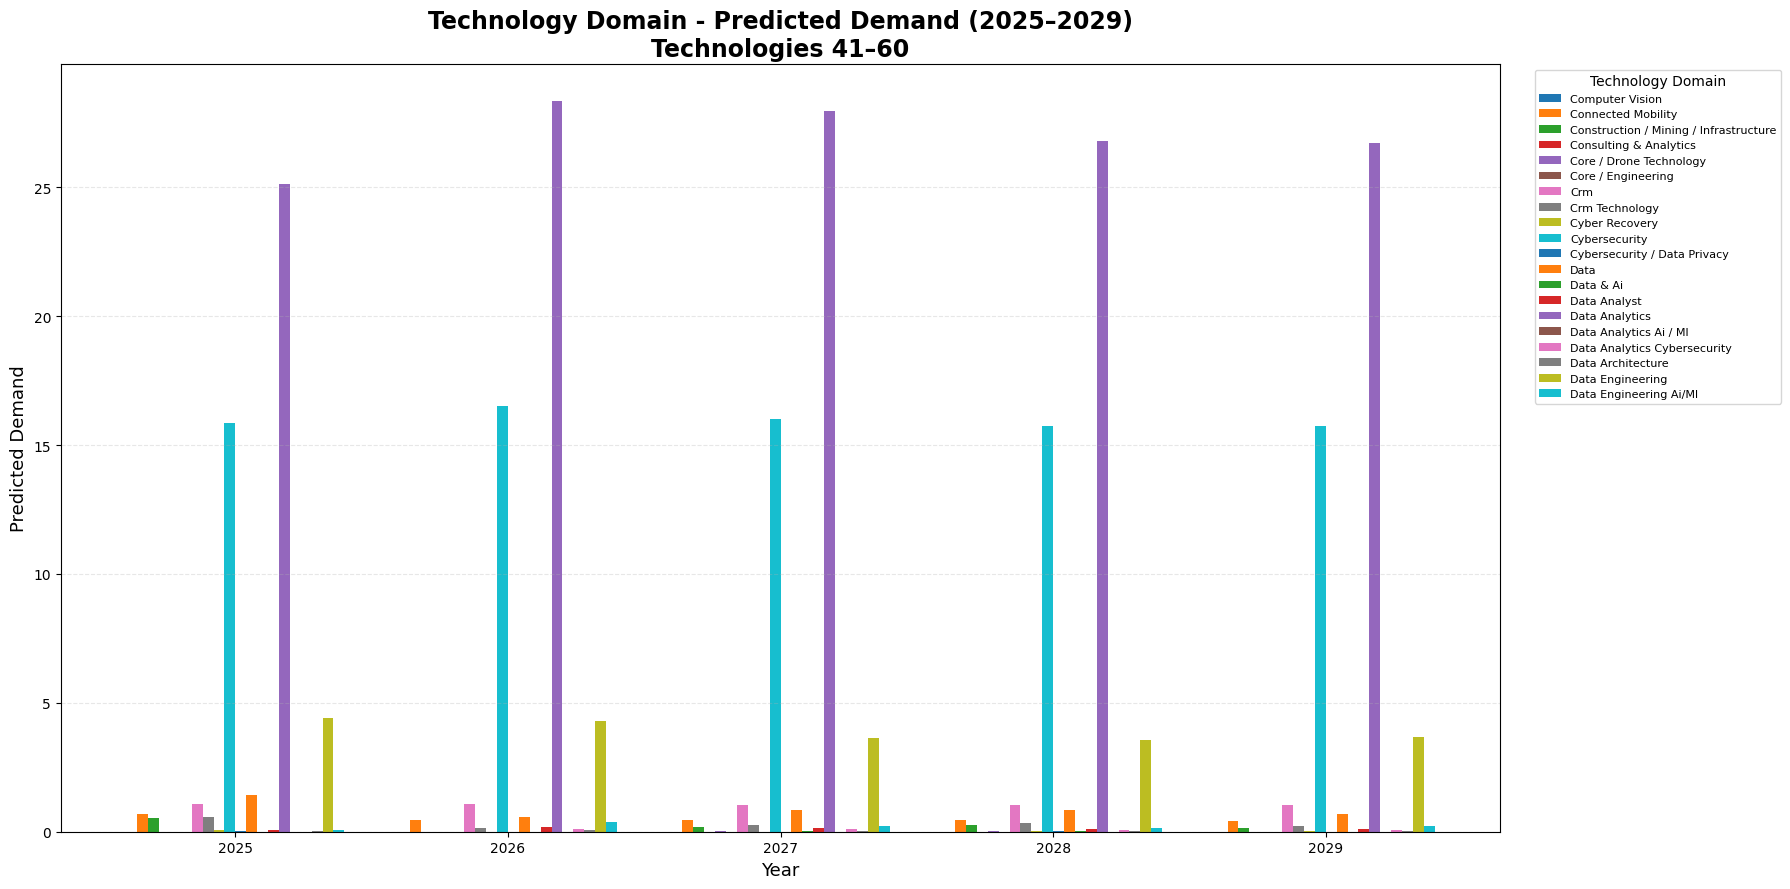

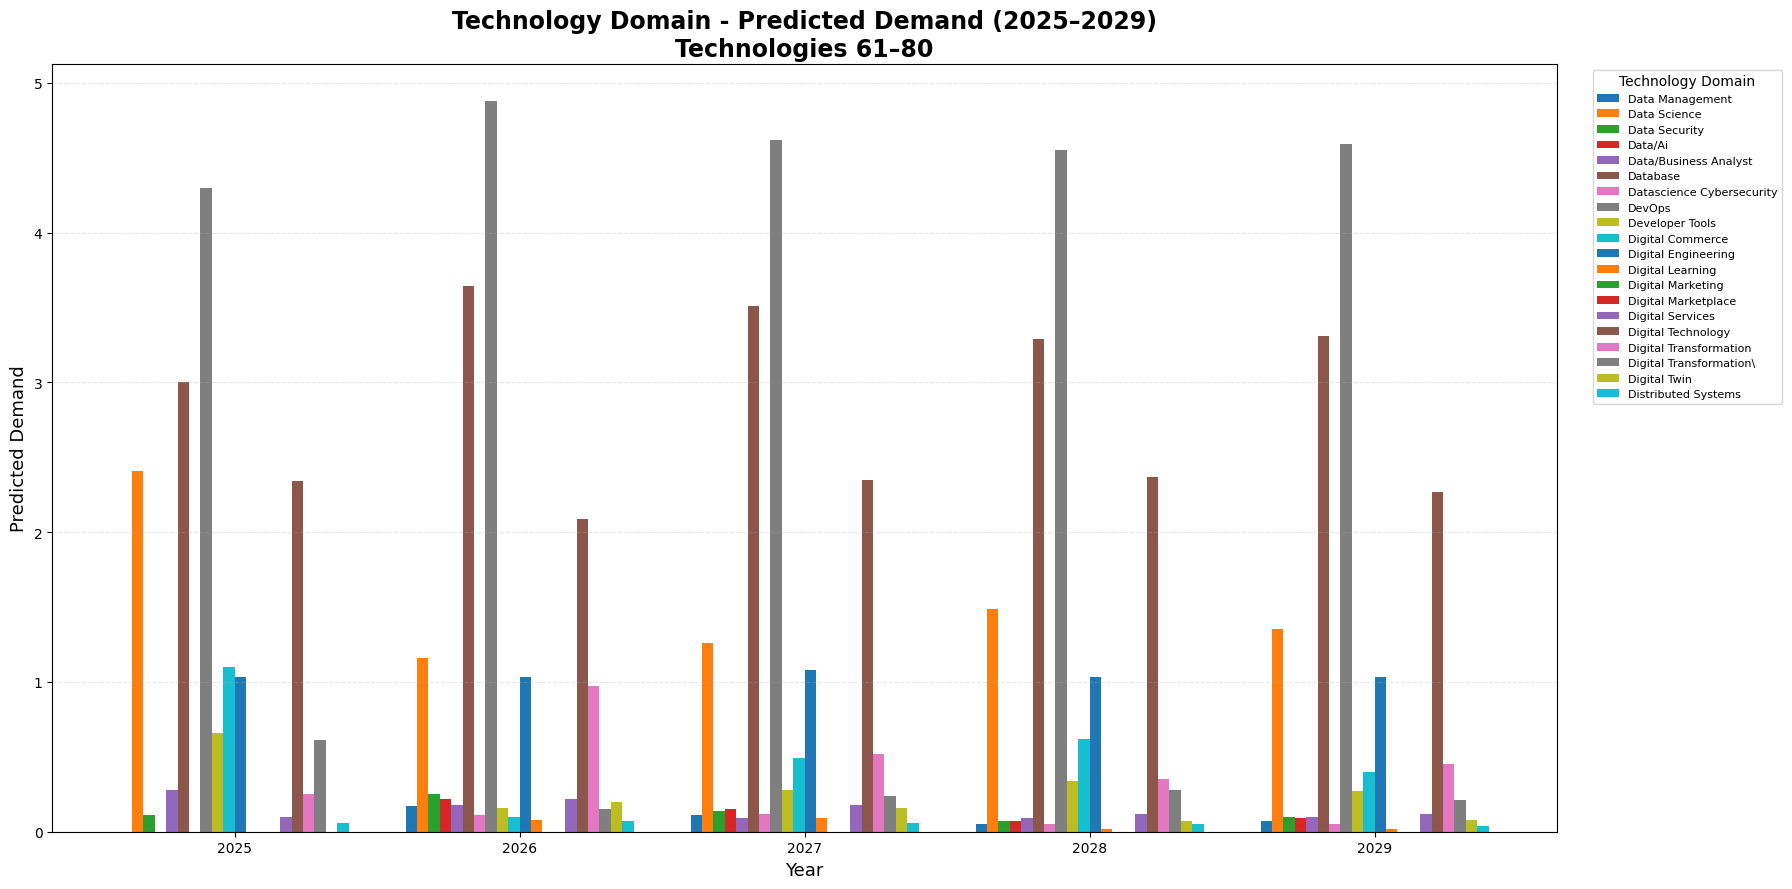

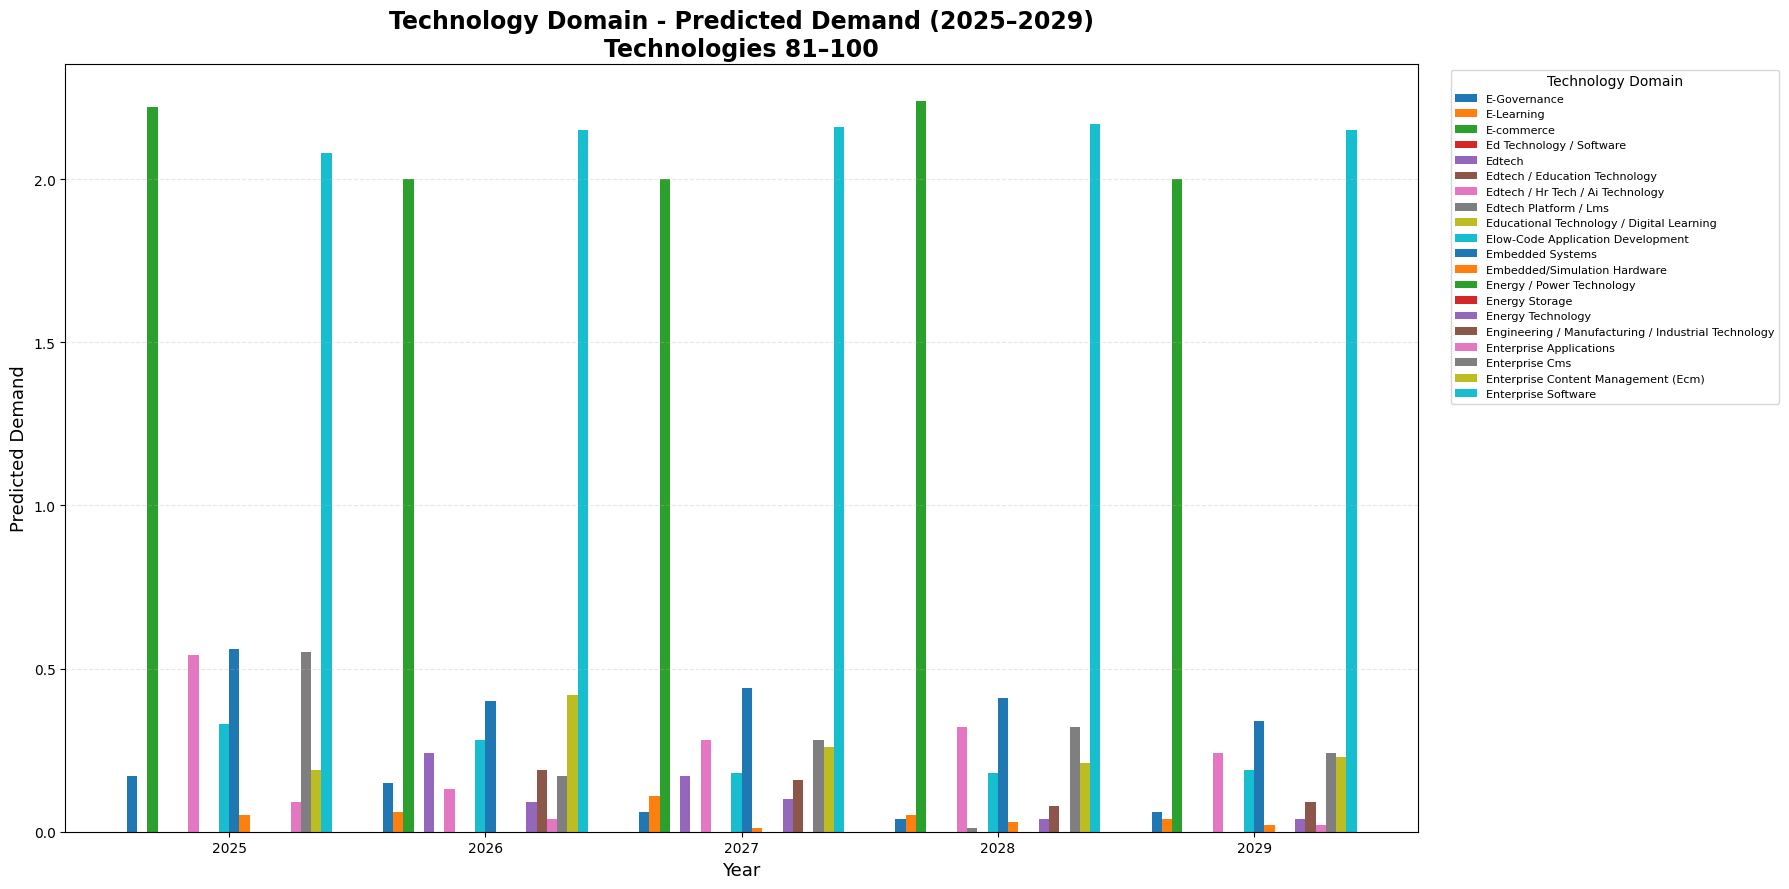

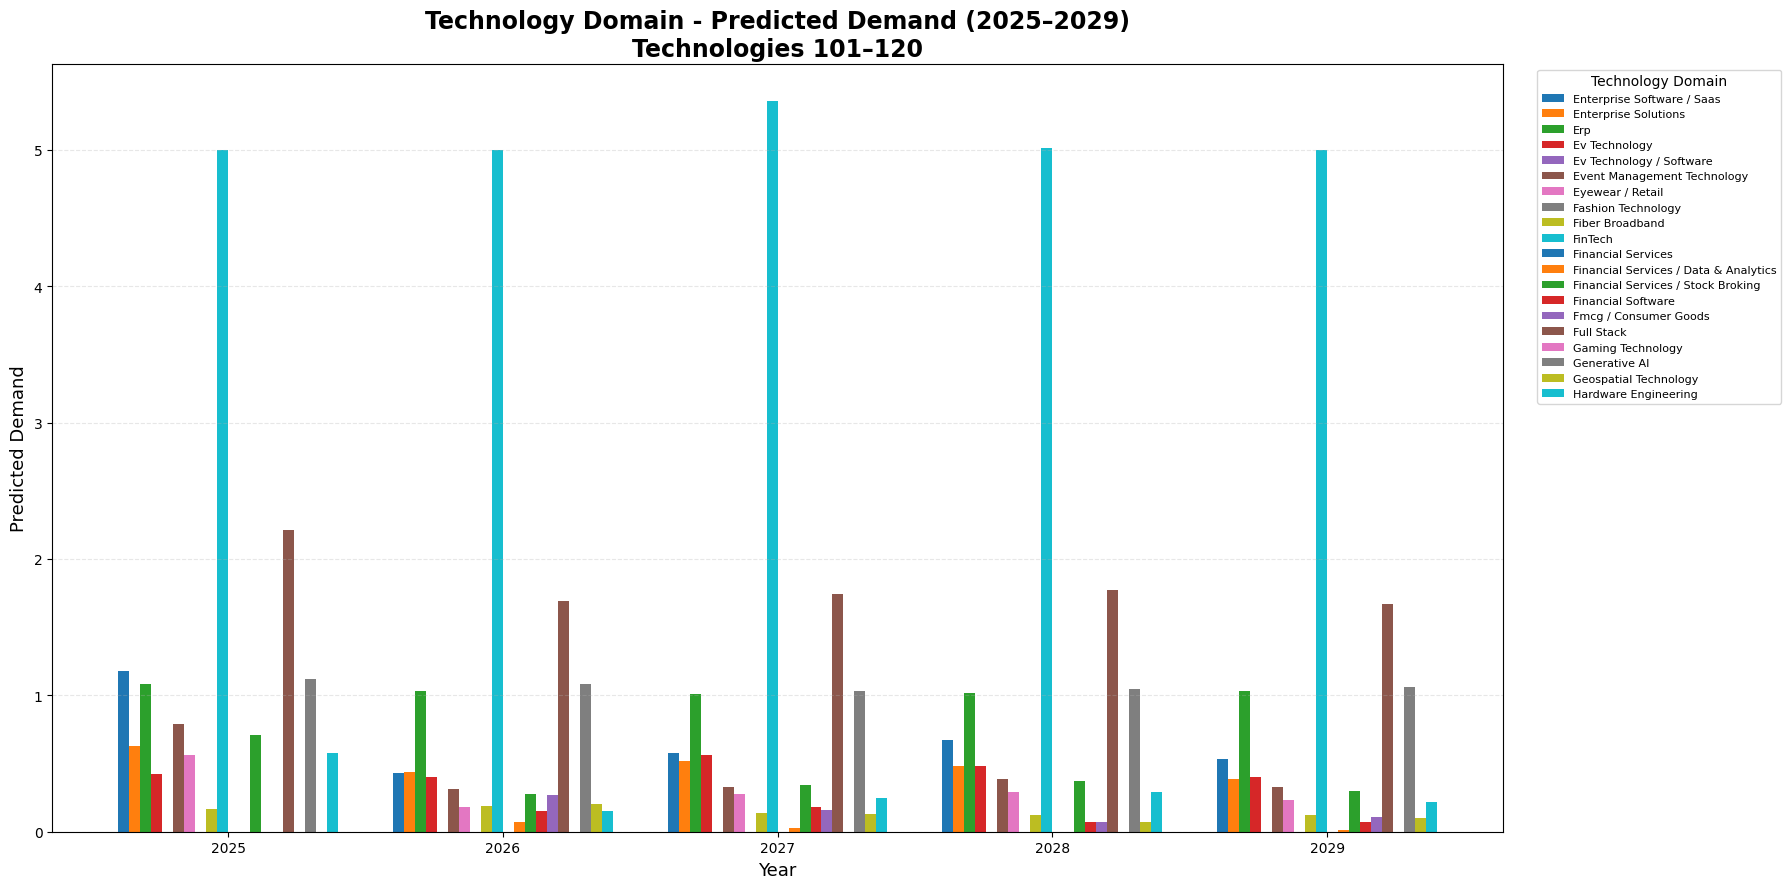

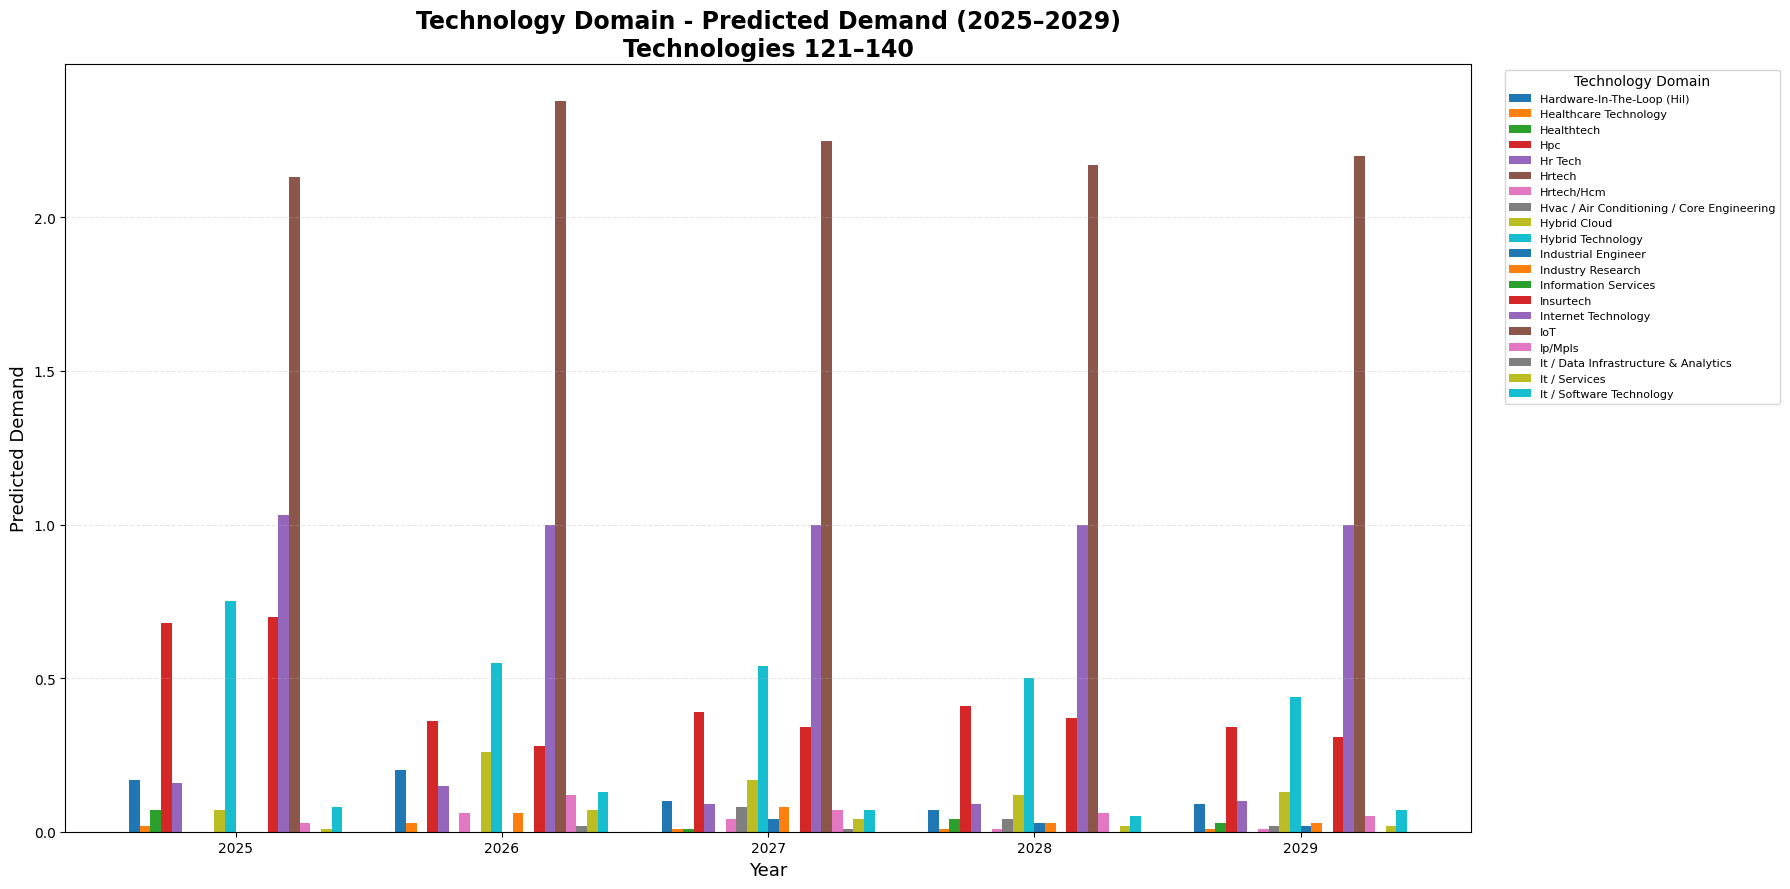

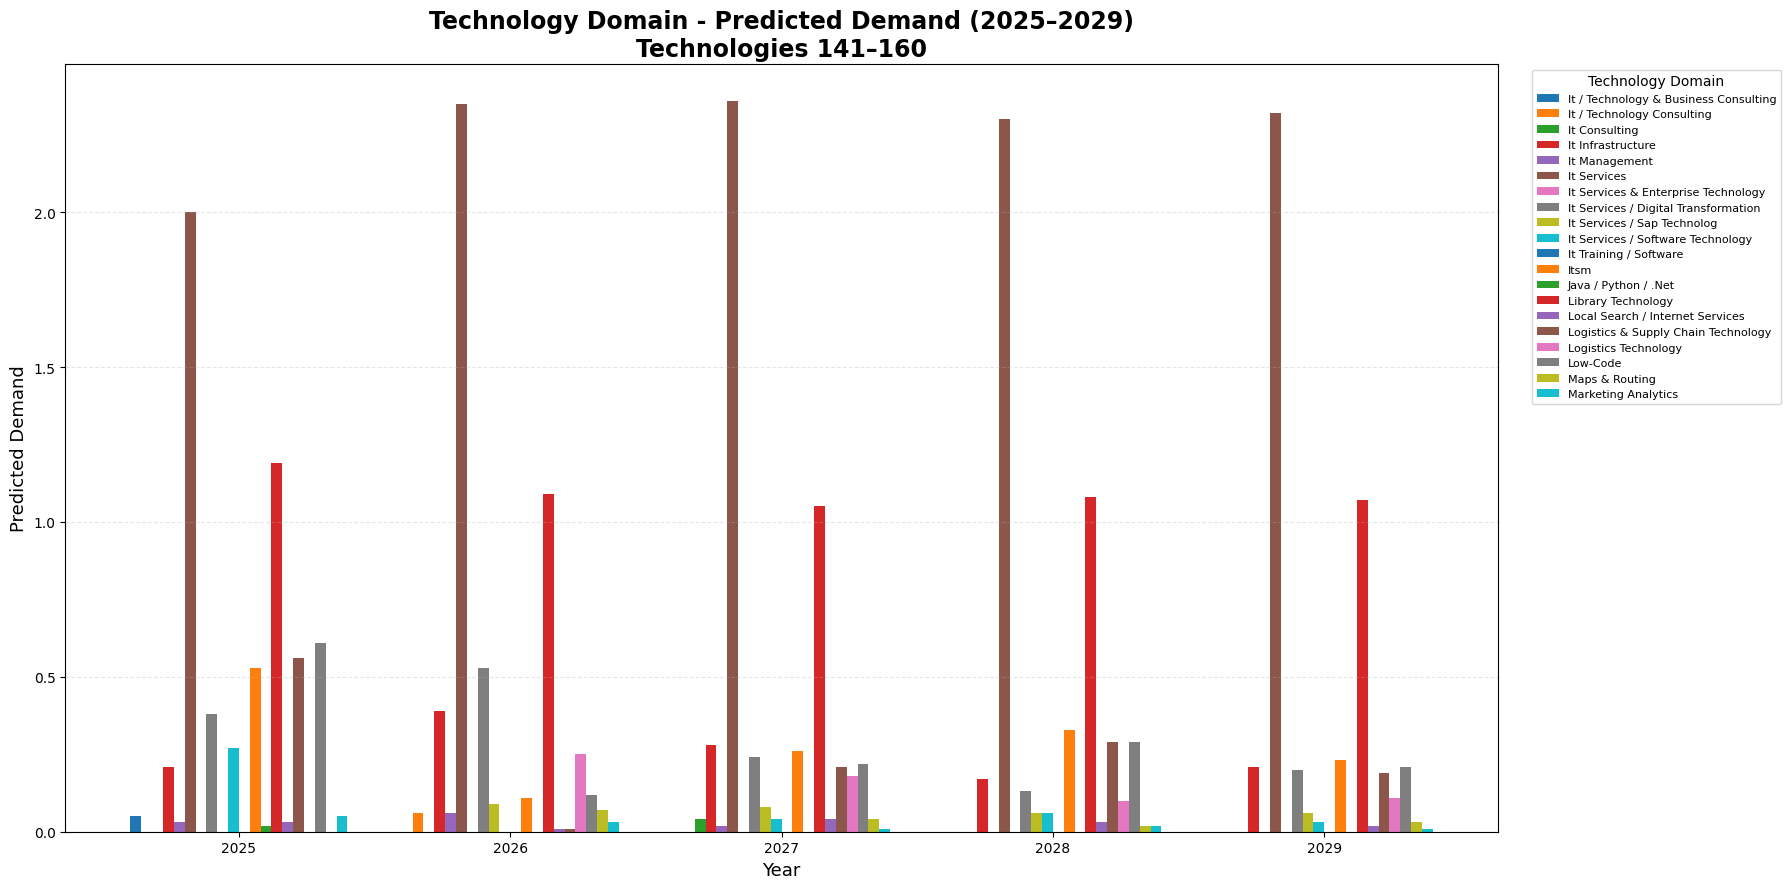

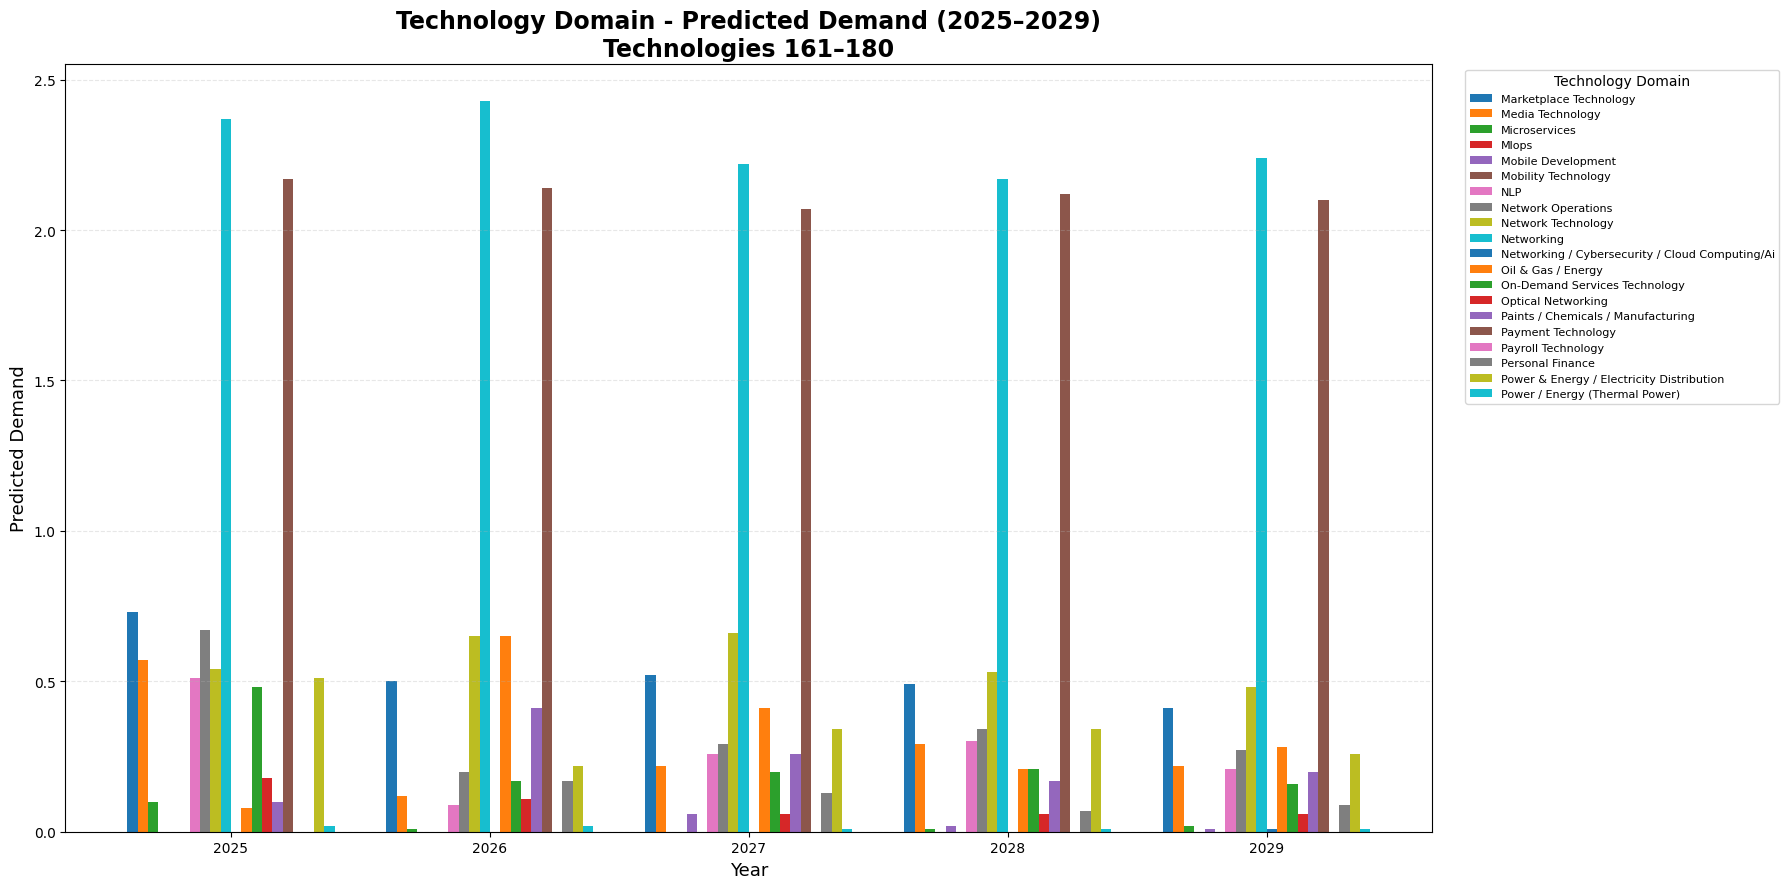

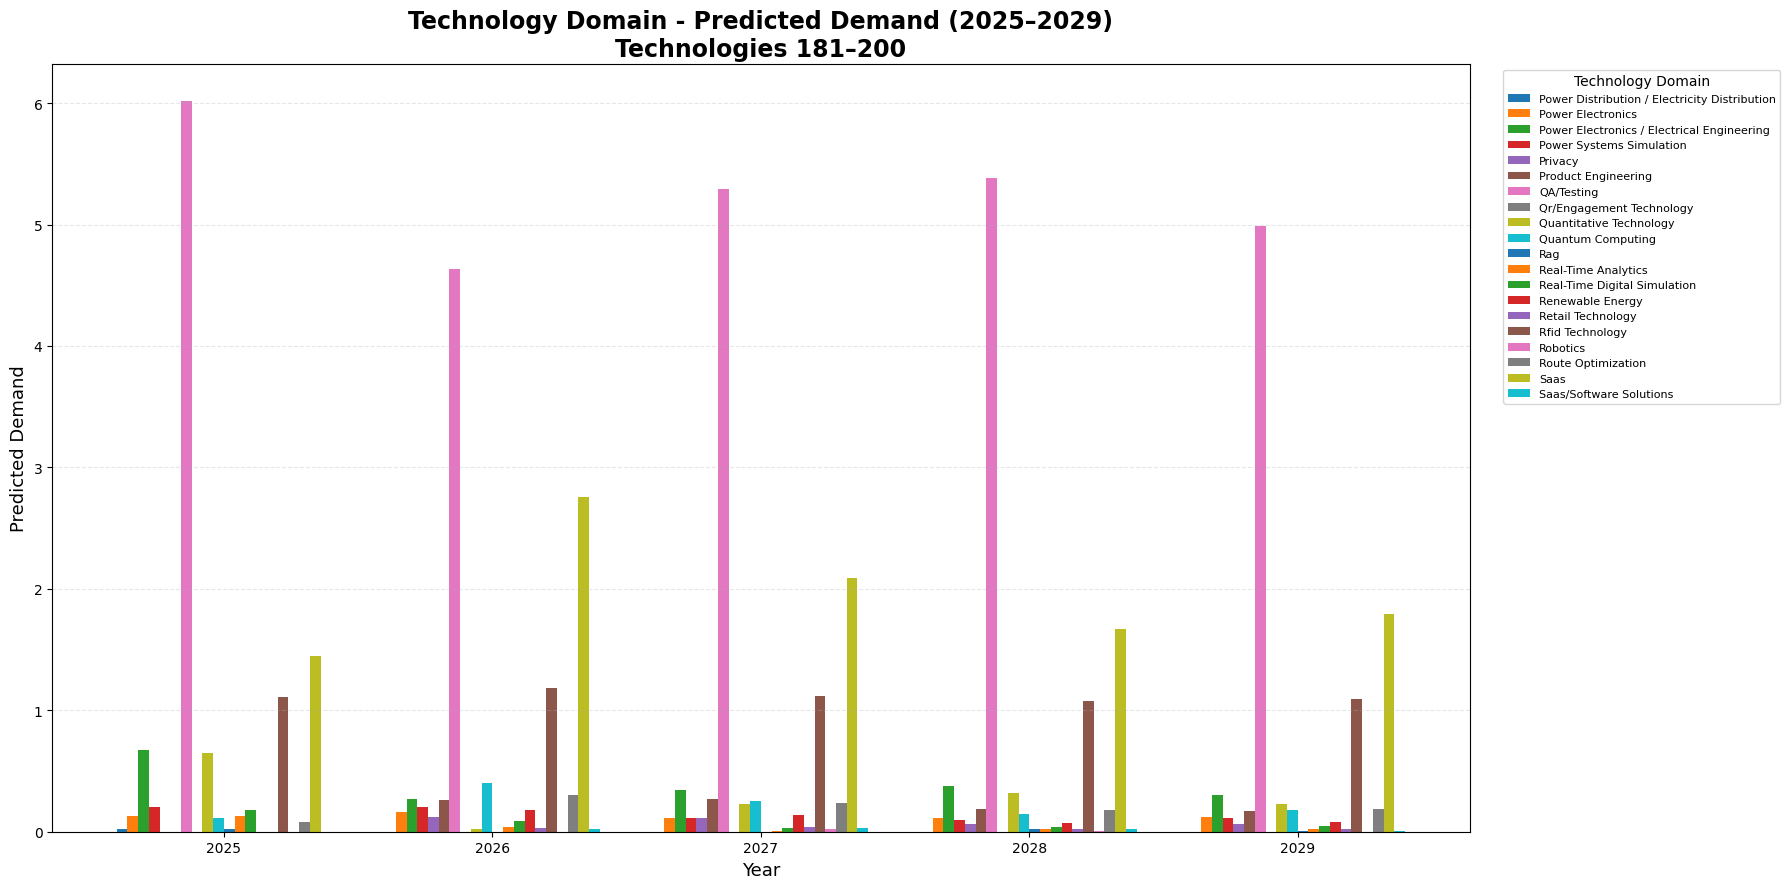

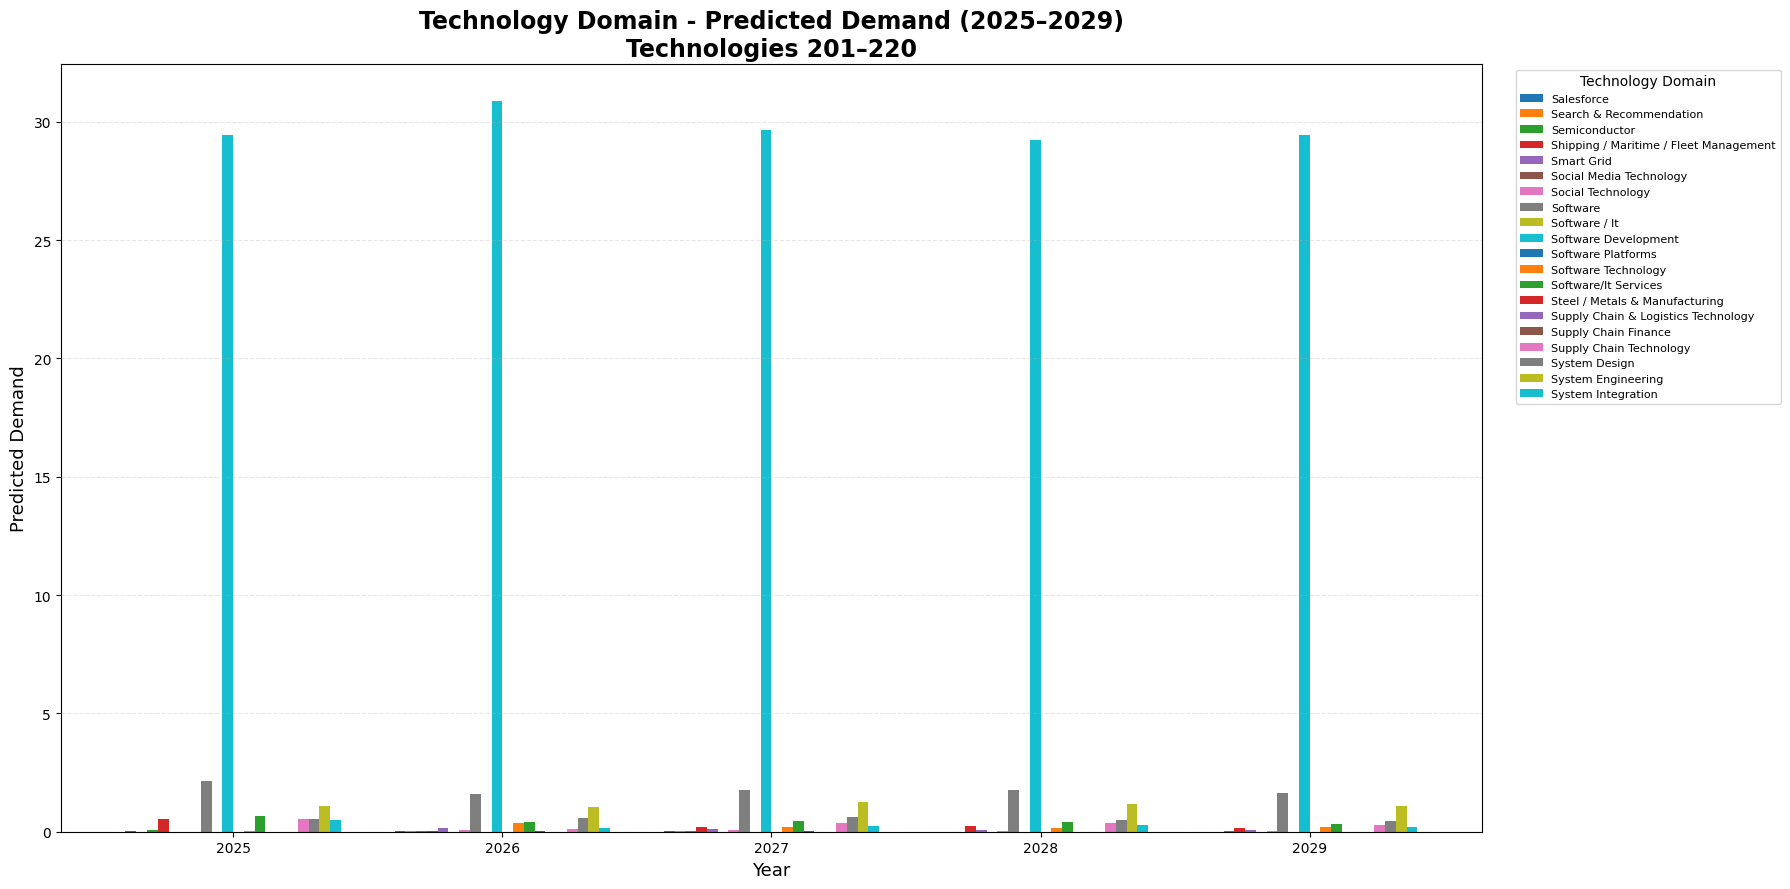

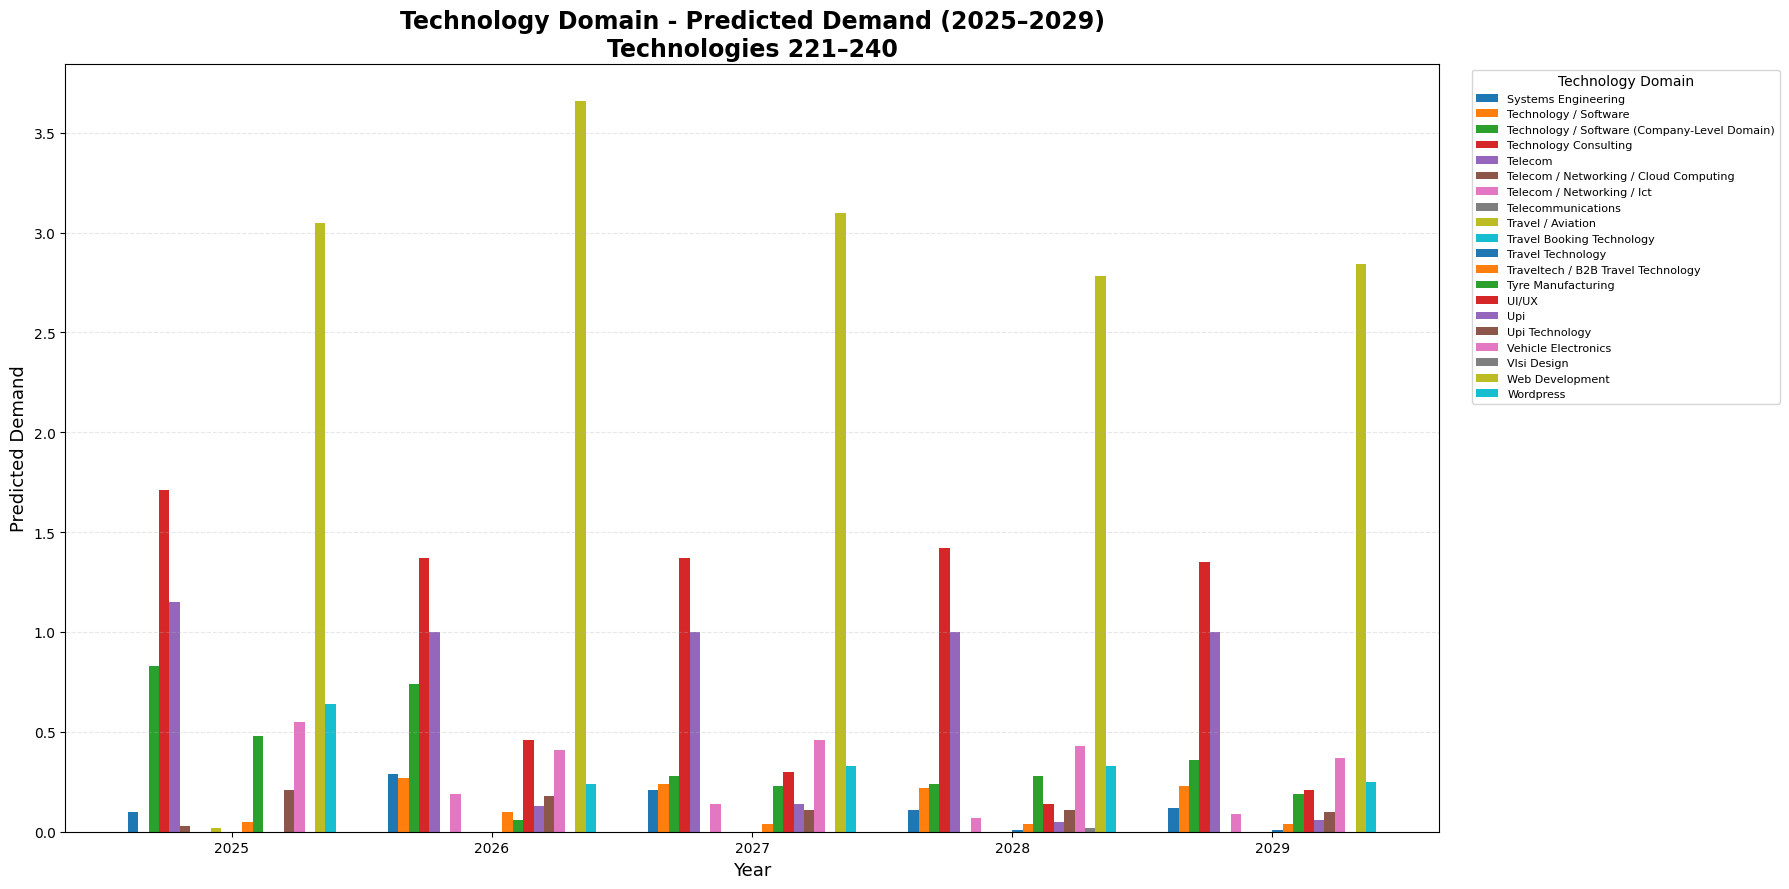

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# ==========================================
# ALL TECHNOLOGIES - YEAR-WISE PREDICTION
# ==========================================

# Technology names
technologies = prediction_df.columns.tolist()

# Years
years = prediction_df.index.tolist()

# Number of technologies
n_tech = len(technologies)

print("Total technologies:", n_tech)


# ==========================================
# CREATE GRAPH IN BATCHES
# ==========================================

# 20 technologies per graph
batch_size = 20

for start in range(0, n_tech, batch_size):

    end = min(start + batch_size, n_tech)

    tech_batch = technologies[start:end]

    data = prediction_df[tech_batch]

    x = np.arange(len(years))

    # Width of each bar
    width = 0.8 / len(tech_batch)

    plt.figure(figsize=(18, 9))

    # --------------------------------------
    # Bars for every technology
    # --------------------------------------

    for i, tech in enumerate(tech_batch):

        values = data[tech].values

        offset = (
            i - (len(tech_batch) - 1) / 2
        ) * width

        plt.bar(
            x + offset,
            values,
            width=width,
            label=tech
        )


    # --------------------------------------
    # X-axis = Year
    # --------------------------------------

    plt.xlabel(
        "Year",
        fontsize=13
    )

    plt.ylabel(
        "Predicted Demand",
        fontsize=13
    )

    plt.xticks(
        x,
        years
    )


    # --------------------------------------
    # Title
    # --------------------------------------

    plt.title(
        f"Technology Domain - Predicted Demand "
        f"(2025–2029)\nTechnologies {start + 1}–{end}",
        fontsize=17,
        fontweight="bold"
    )


    # --------------------------------------
    # Grid
    # --------------------------------------

    plt.grid(
        axis="y",
        linestyle="--",
        alpha=0.3
    )


    # --------------------------------------
    # Legend
    # --------------------------------------

    plt.legend(
        title="Technology Domain",
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        fontsize=8
    )


    plt.tight_layout()
    plt.show()